# Oasis Infobyte Data Analytics Internship

## Level 1 – Task 2: Customer Segmentation Analysis

### Project Title
**Customer Segmentation Using RFM Analysis and K-Means Clustering**

### Objective
The objective of this project is to segment an e-commerce company's
customers into meaningful groups based on purchasing behaviour.

RFM (Recency, Frequency, Monetary) analysis is used to create customer-level
behavioural features, followed by StandardScaler and K-Means clustering.

The resulting customer segments can help the business identify valuable,
loyal, occasional, and inactive customers and develop targeted marketing
strategies for each group.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Google Colab
- Streamlit
- Plotly

***STEP 2 — Import Libraries***



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


***STEP 3 — Upload the Online Retail Dataset***

The Online Retail dataset contains transactional data including invoice
information, products, quantities, transaction dates, unit prices,
customer identifiers, and countries.

In [3]:
df = pd.read_excel("/content/Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


***STEP 4 — Initial Data Inspection***

Before performing customer segmentation, the dataset is examined to
understand its structure, data types, missing values, duplicates, and
overall data quality.

In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (541909, 8)


In [5]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [6]:
print("\nData Types:")
print(df.dtypes)


Data Types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object


In [7]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:
print("\nDuplicate Rows:")
print(df.duplicated().sum())



Duplicate Rows:
5268


In [9]:
print("\nUnique Customers:")
print(df["CustomerID"].nunique())



Unique Customers:
4372


In [10]:
print("\nUnique Countries:")
print(df["Country"].nunique())


Unique Countries:
38


In [11]:
print("\nDate Range:")
print("Start Date:", df["InvoiceDate"].min())
print("End Date:", df["InvoiceDate"].max())


Date Range:
Start Date: 2010-12-01 08:26:00
End Date: 2011-12-09 12:50:00


### Observation

The dataset contains 541,909 transaction records with 8 variables.
CustomerID contains a substantial number of missing values, while
Description also contains some missing records. Duplicate transactions
are also present.

Since customer segmentation requires identifying the purchasing behaviour
of individual customers, transactions without a valid CustomerID cannot
be used for RFM analysis and will therefore be removed during cleaning.

***STEP 5 — Dataset Information***

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [13]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


### Observation

The descriptive statistics indicate substantial variation in transaction
quantity and unit price. Invalid or returned transactions may contain
non-positive quantity values. These records need to be handled before
calculating customer spending behaviour.

***STEP 6 — Data Cleaning***



The following cleaning operations are performed:

1. Remove transactions with missing CustomerID.
2. Remove duplicate records.
3. Remove cancelled invoices.
4. Remove transactions with non-positive quantities.
5. Remove transactions with non-positive unit prices.
6. Convert CustomerID into a consistent string format.
7. Ensure InvoiceDate is stored as datetime.

In [14]:
original_rows = len(df)
original_duplicates = df.duplicated().sum()
original_missing_customers = df["CustomerID"].isnull().sum()

print("Original Rows:", original_rows)
print("Duplicate Rows:", original_duplicates)
print("Missing Customer IDs:", original_missing_customers)

Original Rows: 541909
Duplicate Rows: 5268
Missing Customer IDs: 135080


***STEP 7 — Missing CustomerID Remove***

In [15]:
df_clean = df.dropna(subset=["CustomerID"]).copy()

print("Rows After Removing Missing CustomerID:", len(df_clean))

Rows After Removing Missing CustomerID: 406829


Transactions without CustomerID were removed because these transactions
cannot be associated with a specific customer and therefore cannot be
used to calculate customer-level RFM features.

***STEP 8 — Remove Duplicates***

In [16]:
duplicates_before = df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()

print("Duplicate Rows Removed:", duplicates_before)
print("Rows Remaining:", len(df_clean))

Duplicate Rows Removed: 5225
Rows Remaining: 401604


***STEP 9 — Remove Cancelled Transactions***

In [17]:
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)

cancelled_transactions = (
    df_clean["InvoiceNo"]
    .str.startswith("C")
    .sum()
)

print("Cancelled Transactions:", cancelled_transactions)

df_clean = df_clean[
    ~df_clean["InvoiceNo"].str.startswith("C")
].copy()

print("Rows After Removing Cancelled Transactions:", len(df_clean))

Cancelled Transactions: 8872
Rows After Removing Cancelled Transactions: 392732


***STEP 10 — Remove Invalid Quantity and Price***

In [18]:
print(
    "Non-positive Quantity Records:",
    (df_clean["Quantity"] <= 0).sum()
)

print(
    "Non-positive UnitPrice Records:",
    (df_clean["UnitPrice"] <= 0).sum()
)

Non-positive Quantity Records: 0
Non-positive UnitPrice Records: 40


In [19]:
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

print("Rows After Removing Invalid Transactions:", len(df_clean))

Rows After Removing Invalid Transactions: 392692


***STEP 11 — Correct Data Types***

In [20]:
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

df_clean["CustomerID"] = (
    df_clean["CustomerID"]
    .astype(int)
    .astype(str)
)

print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID             object
Country                object
dtype: object


***STEP 12 — Final Cleaning Check***

In [21]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nUnique Customers:")
print(df_clean["CustomerID"].nunique())

Final Dataset Shape: (392692, 8)

Missing Values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

Duplicate Rows:
0

Unique Customers:
4338


### Data Cleaning Summary

After cleaning, the dataset contains valid completed transactions with
identifiable customers. Missing customer identifiers, duplicate records,
cancelled invoices, and invalid quantity or price records were removed.

The cleaned dataset is now suitable for customer-level behavioural
analysis and RFM feature engineering.

***STEP 13 — Create TotalPrice***

In [22]:
df_clean["TotalPrice"] = (
    df_clean["Quantity"] *
    df_clean["UnitPrice"]
)

df_clean[
    [
        "InvoiceNo",
        "CustomerID",
        "Quantity",
        "UnitPrice",
        "TotalPrice"
    ]
].head()

,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalPrice
0,536365,17850,6,2.55,15.30
1,536365,17850,6,3.39,20.34
2,536365,17850,8,2.75,22.00
3,536365,17850,6,3.39,20.34
4,536365,17850,6,3.39,20.34


***STEP 14 — Overall Purchase Statistics***

In [23]:
total_revenue = df_clean["TotalPrice"].sum()

unique_customers = df_clean["CustomerID"].nunique()

unique_orders = df_clean["InvoiceNo"].nunique()

average_transaction_value = (
    df_clean
    .groupby("InvoiceNo")["TotalPrice"]
    .sum()
    .mean()
)

print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Unique Orders: {unique_orders:,}")
print(f"Average Order Value: £{average_transaction_value:,.2f}")

Total Revenue: £8,887,208.89
Unique Customers: 4,338
Unique Orders: 18,532
Average Order Value: £479.56


***STEP 15 — Purchase Frequency per Customer***

In [24]:
customer_frequency = (
    df_clean
    .groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print(
    "Average Purchase Frequency:",
    round(customer_frequency.mean(), 2)
)

print(
    "Median Purchase Frequency:",
    customer_frequency.median()
)

Average Purchase Frequency: 4.27
Median Purchase Frequency: 2.0


***STEP 16 — Customer Lifetime Value / Monetary Value***

In [25]:
customer_value = (
    df_clean
    .groupby("CustomerID")["TotalPrice"]
    .sum()
)

print(
    "Average Observed Customer Value:",
    round(customer_value.mean(), 2)
)

print(
    "Median Observed Customer Value:",
    round(customer_value.median(), 2)
)

Average Observed Customer Value: 2048.69
Median Observed Customer Value: 668.57


### Note on Customer Lifetime Value

Because the dataset covers a fixed historical observation period and does
not contain future retention or margin information, total historical
customer spending is used as an observed customer value proxy rather than
a predictive lifetime value estimate.

***STEP 17 — Create RFM Features***

# RFM Analysis

RFM analysis evaluates customer purchasing behaviour using three metrics:

- **Recency:** Number of days since the customer's most recent purchase.
- **Frequency:** Number of unique purchases made by the customer.
- **Monetary:** Total amount spent by the customer.

Lower Recency and higher Frequency and Monetary values generally indicate
more valuable and engaged customers.

***STEP 18 — Snapshot Date***

In [26]:
snapshot_date = (
    df_clean["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

print("Snapshot Date:", snapshot_date)

Snapshot Date: 2011-12-10 12:50:00


***STEP 19 — Build RFM Table***

In [27]:
rfm = (
    df_clean
    .groupby("CustomerID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda x: (snapshot_date - x.max()).days
        ),
        Frequency=(
            "InvoiceNo",
            "nunique"
        ),
        Monetary=(
            "TotalPrice",
            "sum"
        )
    )
    .reset_index()
)

print("RFM Dataset Shape:", rfm.shape)

rfm.head()

RFM Dataset Shape: (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


***STEP 20 — RFM Descriptive Statistics***

In [28]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


### Observation

The RFM statistics show considerable variation in customer behaviour.
Some customers purchase only once, while a smaller group makes purchases
very frequently and contributes substantially more revenue.

The large difference between median and maximum Monetary and Frequency
values also suggests that the dataset contains high-value customer
outliers.

***STEP 21 — RFM Distribution Visualization***

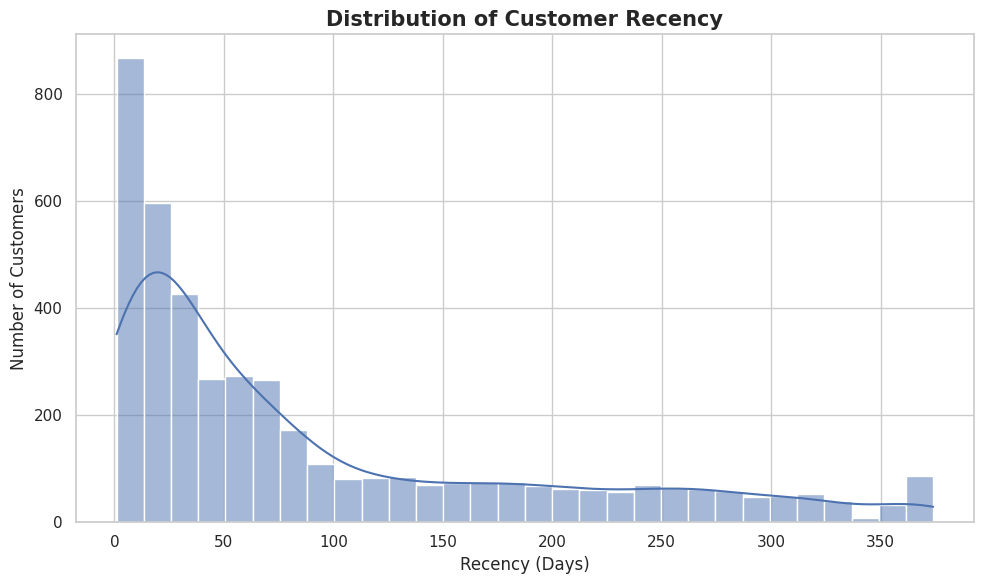

In [29]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=rfm,
    x="Recency",
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Customer Recency",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recency (Days)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Observation

The recency distribution shows that many customers purchased relatively
recently, while another group has not purchased for a considerably longer
period. This difference is useful for identifying active and inactive
customer groups.

***STEP 22 — Frequency Distribution***

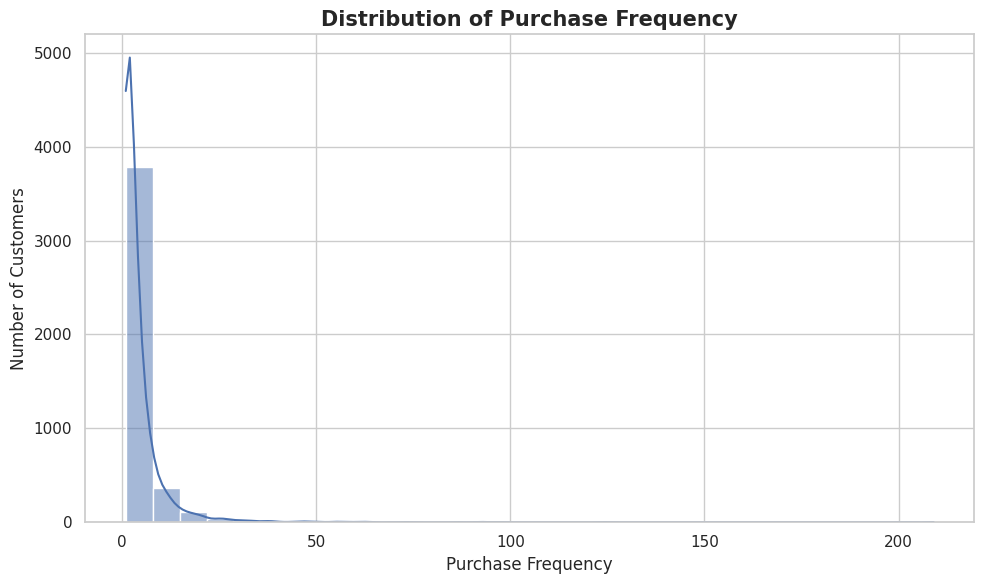

In [30]:
plt.figure(figsize=(10, 6))

sns.histplot(
    rfm["Frequency"],
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Purchase Frequency",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

***STEP 23 — Monetary Distribution***

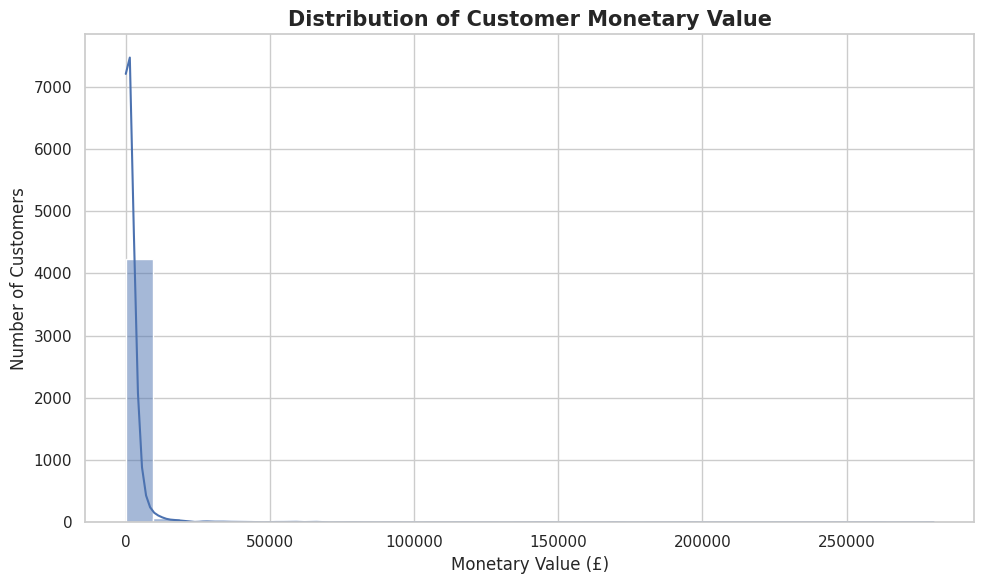

In [31]:
plt.figure(figsize=(10, 6))

sns.histplot(
    rfm["Monetary"],
    bins=30,
    kde=True
)

plt.title(
    "Distribution of Customer Monetary Value",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Monetary Value (£)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

***STEP 24 — RFM Correlation Heatmap***

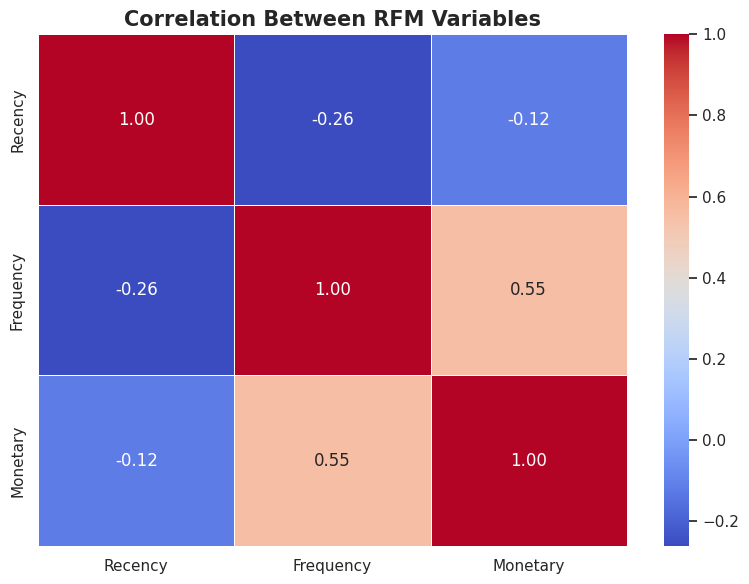

In [32]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    rfm[
        ["Recency", "Frequency", "Monetary"]
    ].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title(
    "Correlation Between RFM Variables",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

***STEP 25 — Outlier Analysis***

## Outlier Treatment for Clustering

RFM variables are highly skewed because a small number of customers make
exceptionally frequent or high-value purchases.

Instead of deleting these valuable customers, percentile capping is
applied only to the clustering feature copy. The original RFM values are
retained for customer profiling and business interpretation.

In [33]:
rfm_model = rfm[
    ["Recency", "Frequency", "Monetary"]
].copy()

for column in rfm_model.columns:

    lower = rfm_model[column].quantile(0.01)
    upper = rfm_model[column].quantile(0.99)

    rfm_model[column] = rfm_model[column].clip(
        lower=lower,
        upper=upper
    )

rfm_model.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.500692,4.008760,1592.644234
std,99.914624,4.863497,2788.353651
min,1.000000,1.000000,52.200000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,369.000000,30.000000,19780.487800


***STEP 26 — Log Transformation***

In [34]:
rfm_log = rfm_model.copy()

rfm_log["Recency"] = np.log1p(
    rfm_log["Recency"]
)

rfm_log["Frequency"] = np.log1p(
    rfm_log["Frequency"]
)

rfm_log["Monetary"] = np.log1p(
    rfm_log["Monetary"]
)

rfm_log.head()

,Recency,Frequency,Monetary
0,5.789960,0.693147,9.892502
1,1.098612,2.079442,8.368925
2,4.330733,1.609438,7.494564
3,2.995732,0.693147,7.472245
4,5.739793,0.693147,5.815324


Log transformation is applied to reduce the strong right-skewness of RFM
features before standardisation and K-Means clustering.

***STEP 27 — StandardScaler***

In [35]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(
    rfm_log[
        ["Recency", "Frequency", "Monetary"]
    ]
)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=[
        "Recency",
        "Frequency",
        "Monetary"
    ],
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
0,1.462228,-0.974100,2.724304
1,-2.038890,1.110952,1.469394
2,0.373218,0.404045,0.749216
3,-0.623084,-0.974100,0.730833
4,1.424788,-0.974100,-0.633907


***STEP 28 — Check Standardized Data***

In [36]:
print(
    rfm_scaled.describe().round(2)
)

       Recency  Frequency  Monetary
count  4338.00    4338.00   4338.00
mean     -0.00       0.00     -0.00
std       1.00       1.00      1.00
min      -2.34      -0.97     -2.15
25%      -0.66      -0.97     -0.71
50%       0.09      -0.36     -0.06
75%       0.84       0.68      0.68
max       1.55       3.15      2.72


***STEP 29 — Elbow Method***

# Determining the Optimal Number of Clusters

The Elbow Method is used to evaluate different values of K. The within-
cluster sum of squares (inertia) is calculated for each candidate K.
The point where the improvement begins to diminish provides guidance for
selecting an appropriate number of clusters.

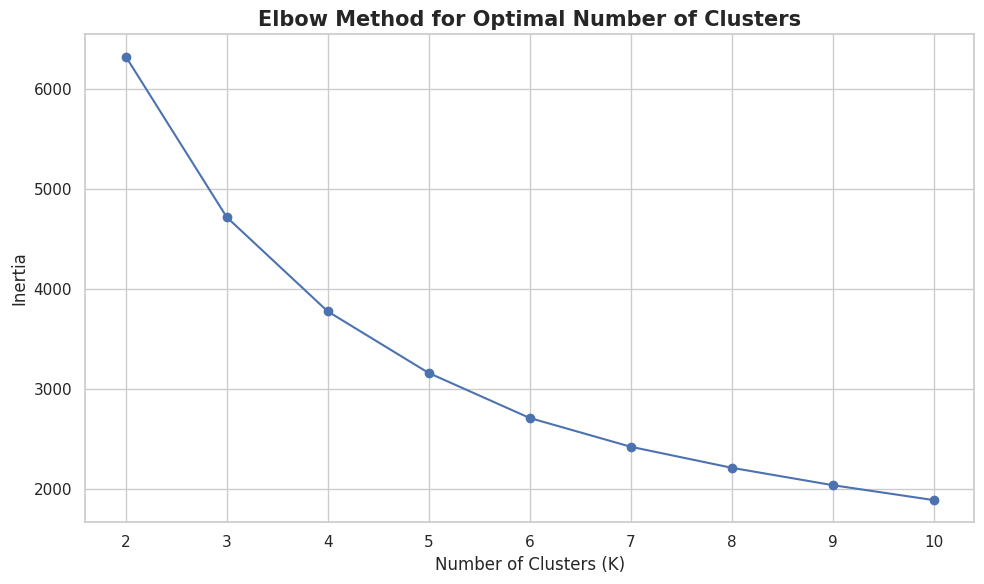

In [37]:
inertia = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    list(k_values),
    inertia,
    marker="o"
)

plt.title(
    "Elbow Method for Optimal Number of Clusters",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

***STEP 30 — Silhouette Scores***

In [38]:
silhouette_results = {}

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_results[k] = score

silhouette_df = pd.DataFrame({
    "K": silhouette_results.keys(),
    "Silhouette Score": silhouette_results.values()
})

silhouette_df

,K,Silhouette Score
0,2,0.436136
1,3,0.337410
2,4,0.339388
3,5,0.316087
4,6,0.314766
5,7,0.310766
6,8,0.305960
7,9,0.284282
8,10,0.282671


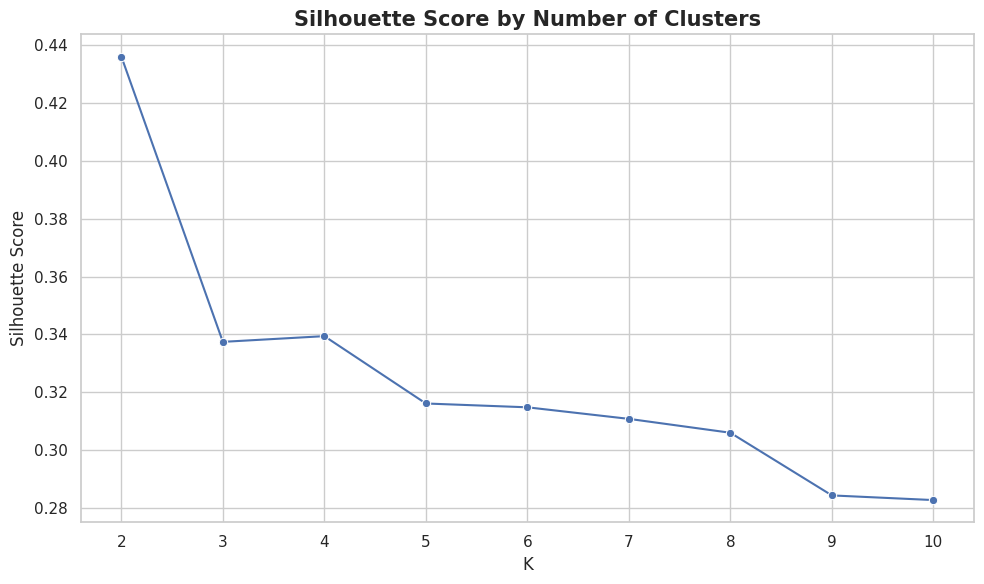

In [39]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=silhouette_df,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title(
    "Silhouette Score by Number of Clusters",
    fontsize=15,
    fontweight="bold"
)

plt.xticks(range(2, 11))

plt.tight_layout()
plt.show()

## ***STEP 31 — Final K-Means Clustering***

Four clusters are selected to provide more detailed and actionable
customer segmentation.

Although K=2 achieved the highest Silhouette Score (0.4361),
K=4 provides a more granular segmentation with a Silhouette Score
of 0.3394.

The four-cluster solution is therefore selected for business
interpretability, subject to cluster profile validation.

In [40]:
optimal_k = 4

final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

print("K-Means Clustering Completed!")
print("Number of Clusters:", optimal_k)

display(rfm.head(10))

K-Means Clustering Completed!
Number of Clusters: 4


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,2,7,4310.00,2
2,12348,75,4,1797.24,3
3,12349,19,1,1757.55,0
4,12350,310,1,334.40,1
5,12352,36,8,2506.04,3
6,12353,204,1,89.00,1
7,12354,232,1,1079.40,1
8,12355,214,1,459.40,1
9,12356,23,3,2811.43,3






***STEP 32 — Final Model Evaluation***

In [41]:
final_silhouette = silhouette_score(
    rfm_scaled,
    rfm["Cluster"]
)

print("Final K:", optimal_k)
print("Silhouette Score:", round(final_silhouette, 4))
print("Inertia:", round(final_kmeans.inertia_, 2))

Final K: 4
Silhouette Score: 0.3394
Inertia: 3772.93


***STEP 33 — Number of Customers per Cluster***

In [42]:
cluster_counts = (
    rfm["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_percentage = (
    cluster_counts / len(rfm) * 100
).round(2)

cluster_distribution = pd.DataFrame({
    "Customers": cluster_counts,
    "Percentage (%)": cluster_percentage
})

display(cluster_distribution)

,Customers,Percentage (%)
Cluster,,
0,836,19.27
1,1597,36.81
2,735,16.94
3,1170,26.97


***STEP 34 — Cluster Distribution Bar Chart***

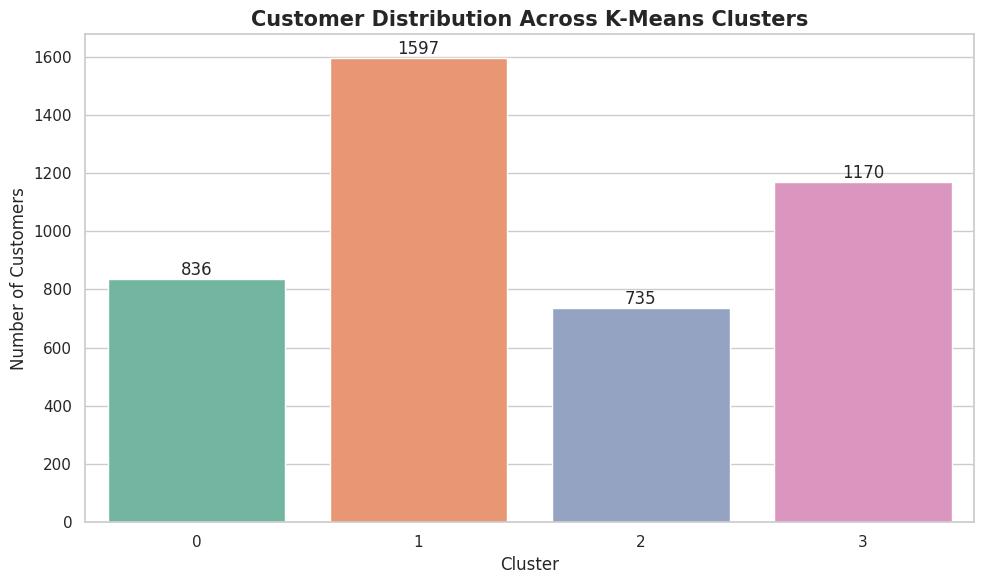

In [43]:
plt.figure(figsize=(10, 6))

ax = sns.countplot(
    data=rfm,
    x="Cluster",
    hue="Cluster",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title(
    "Customer Distribution Across K-Means Clusters",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Observation

The bar chart shows the distribution of customers across the four
K-Means clusters. Differences in cluster sizes indicate that customer
purchasing behaviour is not uniformly distributed.

The business significance of each cluster is determined by examining
its Recency, Frequency, and Monetary characteristics.

***STEP 35 — Cluster Visualization 1: Recency vs Frequency***

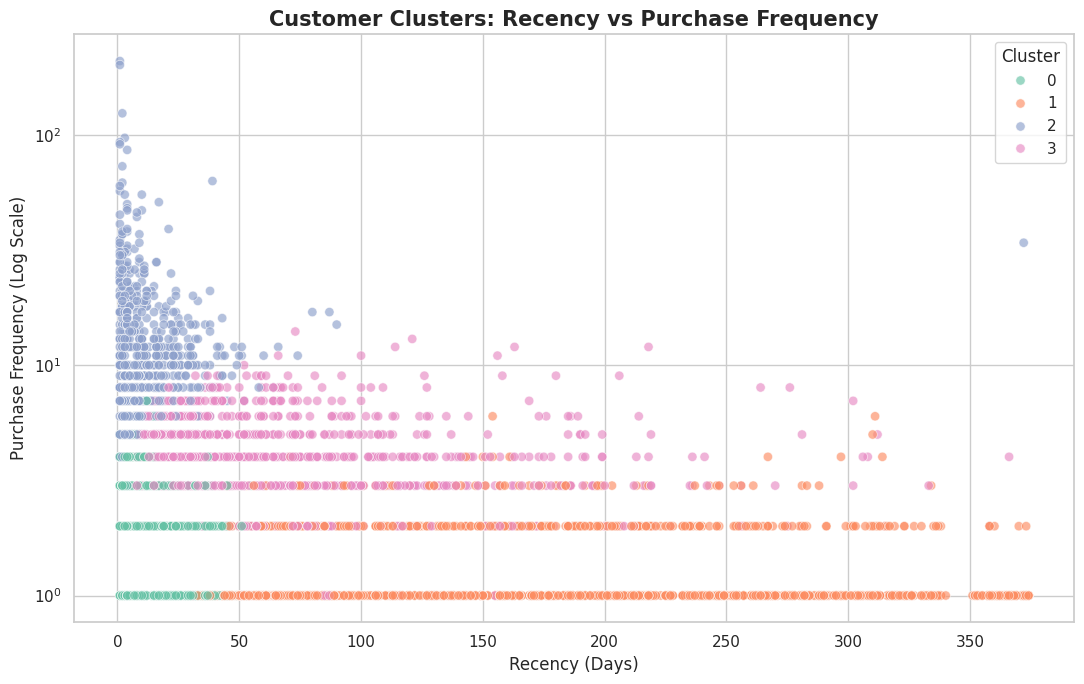

In [44]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="Set2",
    alpha=0.65,
    s=45
)

plt.yscale("log")

plt.title(
    "Customer Clusters: Recency vs Purchase Frequency",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recency (Days)")
plt.ylabel("Purchase Frequency (Log Scale)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

***STEP 36 — Cluster Visualization 2: Frequency vs Monetary***

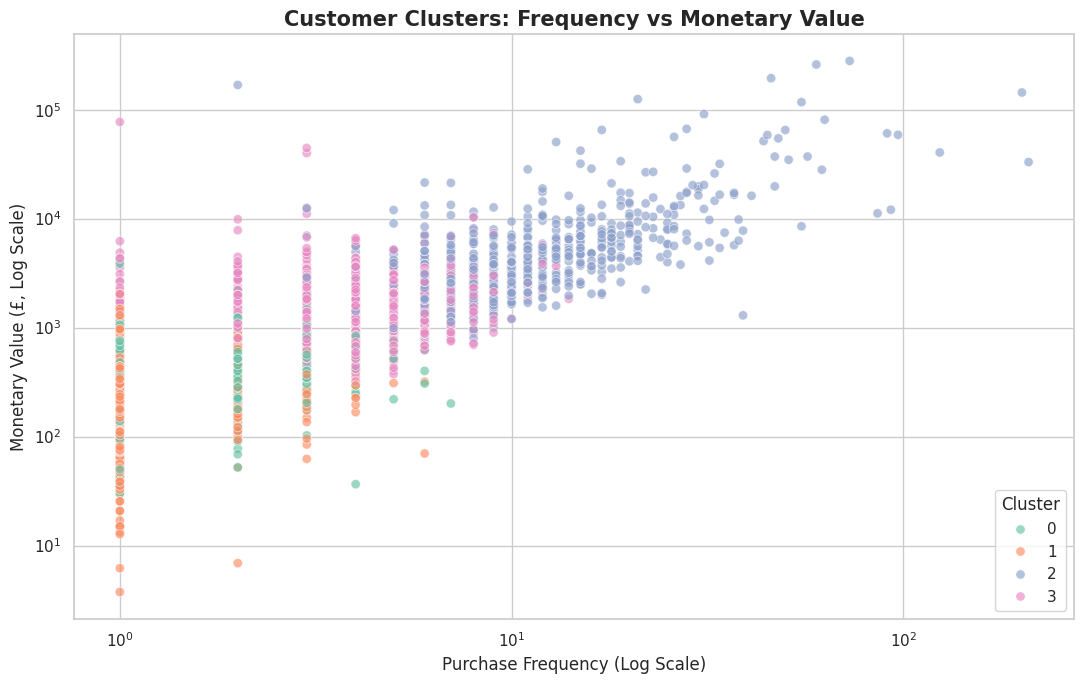

In [45]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.65,
    s=45
)

plt.xscale("log")
plt.yscale("log")

plt.title(
    "Customer Clusters: Frequency vs Monetary Value",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Purchase Frequency (Log Scale)")
plt.ylabel("Monetary Value (£, Log Scale)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

***STEP 37 — Cluster Visualization 3: Recency vs Monetary***

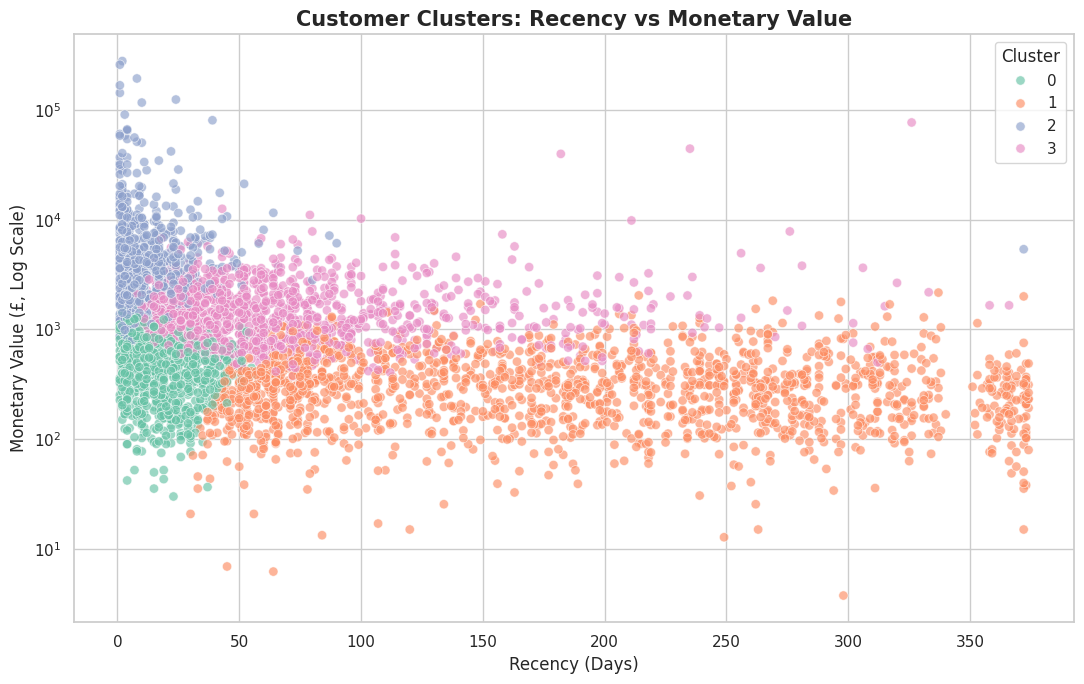

In [46]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.65,
    s=45
)

plt.yscale("log")

plt.title(
    "Customer Clusters: Recency vs Monetary Value",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (£, Log Scale)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

***STEP 38 — Cluster Profiling***

In [47]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Median_Recency=("Recency", "median"),
        Avg_Frequency=("Frequency", "mean"),
        Median_Frequency=("Frequency", "median"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
)

display(cluster_profile)

,Customers,Avg_Recency,Median_Recency,Avg_Frequency,Median_Frequency,Avg_Monetary,Median_Monetary,Total_Revenue
Cluster,,,,,,,,
0,836,19.14,18.0,2.06,2.0,523.35,454.67,437521.02
1,1597,183.98,178.0,1.32,1.0,343.82,296.64,549086.01
2,735,12.17,8.0,13.50,10.0,7905.99,3653.75,5810901.95
3,1170,70.65,55.0,4.08,4.0,1786.07,1338.56,2089699.91


***STEP 39 — Revenue Contribution by Cluster***

In [48]:
cluster_revenue = (
    rfm.groupby("Cluster")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

cluster_revenue_pct = (
    cluster_revenue / cluster_revenue.sum() * 100
).round(2)

revenue_table = pd.DataFrame({
    "Total Revenue (£)": cluster_revenue,
    "Revenue Contribution (%)": cluster_revenue_pct
})

display(revenue_table)

,Total Revenue (£),Revenue Contribution (%)
Cluster,,
2,5810901.950,65.39
3,2089699.913,23.51
1,549086.011,6.18
0,437521.020,4.92


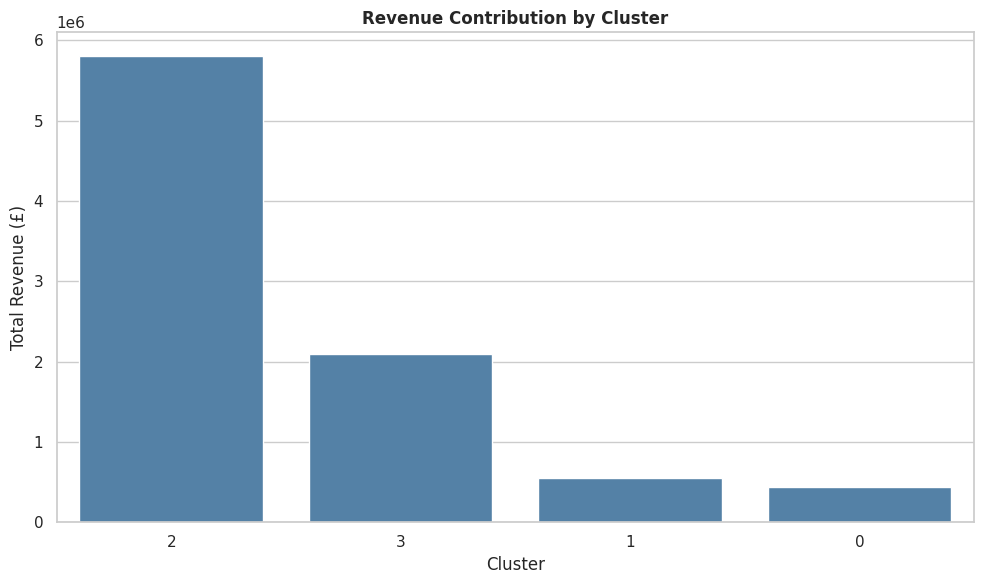

In [49]:
#Graph

plt.figure(figsize=(10, 6))

sns.barplot(
    x=cluster_revenue.index.astype(str),
    y=cluster_revenue.values,
    color="steelblue"
)

plt.title("Revenue Contribution by Cluster", fontweight="bold")
plt.xlabel("Cluster")
plt.ylabel("Total Revenue (£)")
plt.tight_layout()
plt.show()

***STEP 40 — Cluster RFM Heatmap***

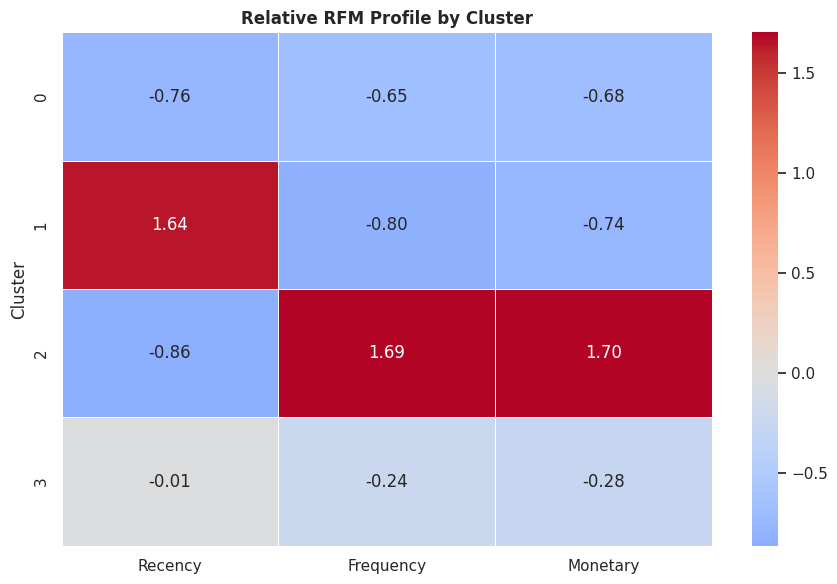

In [50]:
rfm_means = (
    rfm.groupby("Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ]
    .mean()
)

rfm_std = rfm_means.std(ddof=0).replace(0, 1)

normalized_profile = (
    rfm_means - rfm_means.mean()
) / rfm_std

plt.figure(figsize=(9, 6))

sns.heatmap(
    normalized_profile,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Relative RFM Profile by Cluster", fontweight="bold")
plt.tight_layout()
plt.show()

***STEP 41 — Customer Segment Naming***

In [51]:
profile = (
    rfm.groupby("Cluster")
    .agg(
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
)

# Higher scores should indicate more desirable behaviour.
# Low Recency is desirable; high Frequency and Monetary are desirable.

profile["R_Score"] = (
    profile["Avg_Recency"]
    .rank(ascending=False, method="average")
)

profile["F_Score"] = (
    profile["Avg_Frequency"]
    .rank(ascending=True, method="average")
)

profile["M_Score"] = (
    profile["Avg_Monetary"]
    .rank(ascending=True, method="average")
)

profile["Overall_Score"] = (
    profile["R_Score"] +
    profile["F_Score"] +
    profile["M_Score"]
)

# Rank the four clusters from strongest to weakest
ranked_clusters = (
    profile.sort_values(
        ["Overall_Score", "Avg_Monetary", "Avg_Frequency"],
        ascending=[False, False, False]
    )
    .index
    .tolist()
)

segment_names = [
    "Champions",
    "Loyal / Engaged",
    "Developing Customers",
    "Low-Engagement / At-Risk"
]

segment_map = dict(zip(ranked_clusters, segment_names))

rfm["Segment"] = rfm["Cluster"].map(segment_map)

print("Cluster to Segment Mapping:")
print(segment_map)

display(
    rfm[[
        "CustomerID", "Recency", "Frequency",
        "Monetary", "Cluster", "Segment"
    ]].head(10)
)

Cluster to Segment Mapping:
{2: 'Champions', 3: 'Loyal / Engaged', 0: 'Developing Customers', 1: 'Low-Engagement / At-Risk'}


,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,3,Loyal / Engaged
1,12347,2,7,4310.00,2,Champions
2,12348,75,4,1797.24,3,Loyal / Engaged
3,12349,19,1,1757.55,0,Developing Customers
4,12350,310,1,334.40,1,Low-Engagement / At-Risk
5,12352,36,8,2506.04,3,Loyal / Engaged
6,12353,204,1,89.00,1,Low-Engagement / At-Risk
7,12354,232,1,1079.40,1,Low-Engagement / At-Risk
8,12355,214,1,459.40,1,Low-Engagement / At-Risk
9,12356,23,3,2811.43,3,Loyal / Engaged


***STEP 42 — Final Segment Profile***

In [52]:
segment_profile = (
    rfm.groupby("Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
    .sort_values("Total_Revenue", ascending=False)
)

segment_profile["Customer_Share_Pct"] = (
    segment_profile["Customers"] /
    len(rfm) * 100
).round(2)

segment_profile["Revenue_Share_Pct"] = (
    segment_profile["Total_Revenue"] /
    rfm["Monetary"].sum() * 100
).round(2)

display(segment_profile)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,Customer_Share_Pct,Revenue_Share_Pct
Segment,,,,,,,
Champions,735,12.17,13.50,7905.99,5810901.95,16.94,65.39
Loyal / Engaged,1170,70.65,4.08,1786.07,2089699.91,26.97,23.51
Low-Engagement / At-Risk,1597,183.98,1.32,343.82,549086.01,36.81,6.18
Developing Customers,836,19.14,2.06,523.35,437521.02,19.27,4.92


***STEP 43 — Customer Segment Distribution***

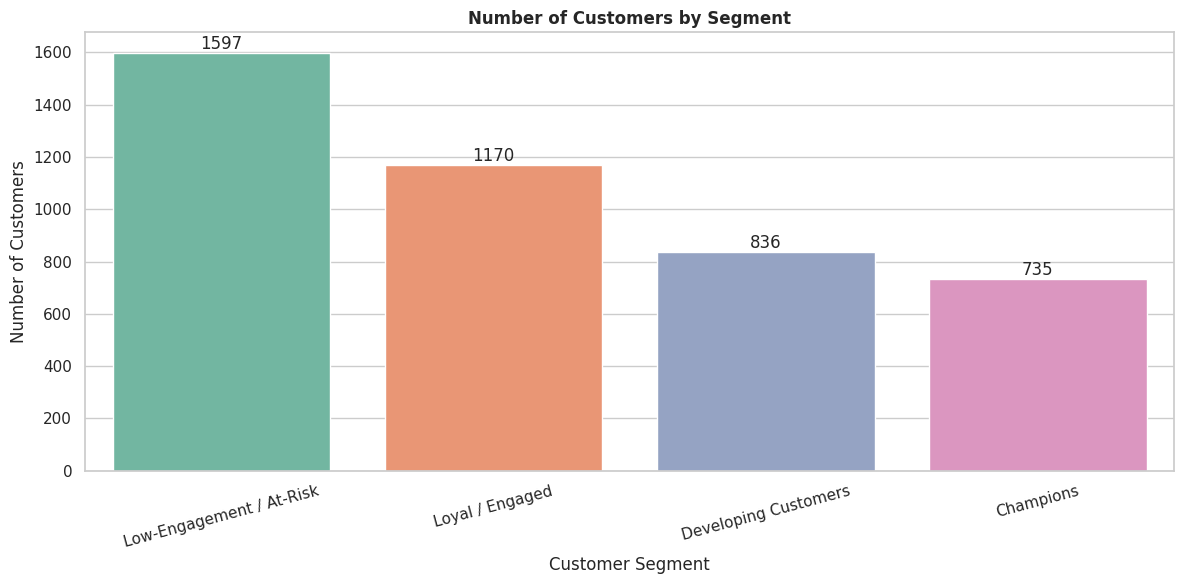

In [53]:
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values,
    hue=segment_counts.index,
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Customers by Segment", fontweight="bold")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

***STEP 44 — Segment Revenue Analysis***

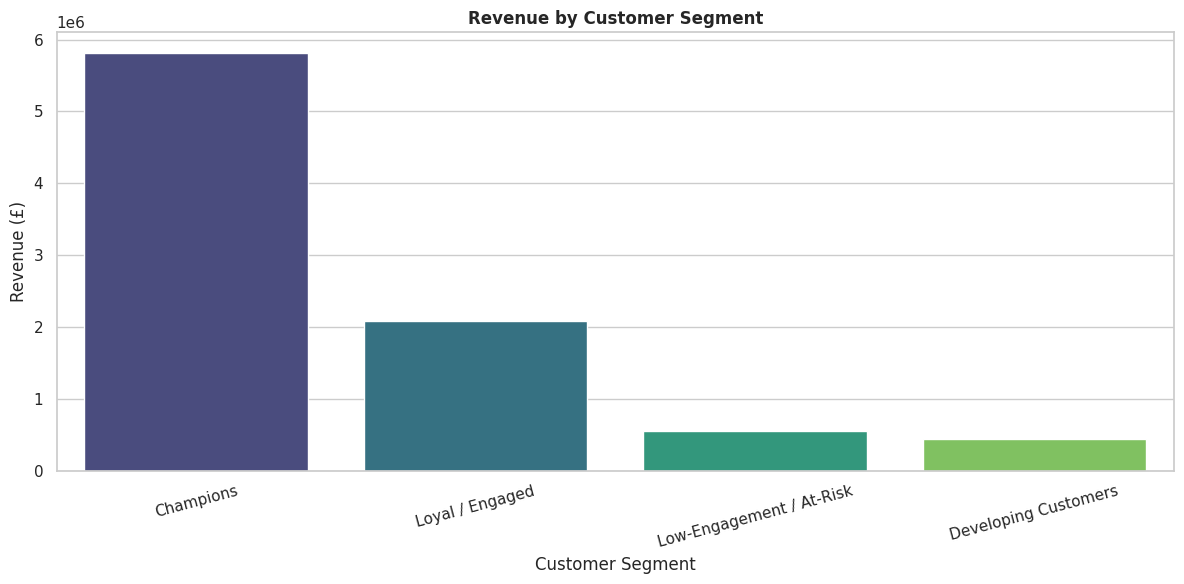

In [54]:
segment_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=segment_revenue.index,
    y=segment_revenue.values,
    hue=segment_revenue.index,
    palette="viridis",
    legend=False
)

plt.title("Revenue by Customer Segment", fontweight="bold")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

***STEP 45 — Customer Purchase Value and Frequency Summary***

In [55]:
order_values = (
    df_clean.groupby(["CustomerID", "InvoiceNo"])["TotalPrice"]
    .sum()
    .reset_index()
)

average_purchase_value = order_values["TotalPrice"].mean()
average_frequency = rfm["Frequency"].mean()
average_customer_value = rfm["Monetary"].mean()

summary_stats = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Total Completed Orders",
        "Average Order Value (£)",
        "Average Purchase Frequency",
        "Average Observed Customer Value (£)",
        "Total Revenue (£)"
    ],
    "Value": [
        rfm["CustomerID"].nunique(),
        df_clean["InvoiceNo"].nunique(),
        average_purchase_value,
        average_frequency,
        average_customer_value,
        rfm["Monetary"].sum()
    ]
})

display(summary_stats.round(2))

,Metric,Value
0,Total Customers,4338.00
1,Total Completed Orders,18532.00
2,Average Order Value (£),479.56
3,Average Purchase Frequency,4.27
4,Average Observed Customer Value (£),2048.69
5,Total Revenue (£),8887208.89


**STEP 46 — Segment-Specific Marketing Recommendations**

# Segment-Based Marketing Recommendations

## Champions
Customers with the strongest overall combination of recent purchases,
purchase frequency, and monetary value.

**Marketing Actions:**
- Provide VIP loyalty benefits.
- Offer exclusive early access to new products.
- Use personalised premium recommendations.
- Prioritise customer retention.

## Loyal / Engaged
Customers with relatively strong purchasing activity and repeat engagement.

**Marketing Actions:**
- Introduce loyalty points and referral rewards.
- Encourage cross-selling and upselling.
- Offer personalised product bundles.
- Strengthen repeat purchase incentives.

## Developing Customers
Customers with opportunities to increase purchase frequency and spending.

**Marketing Actions:**
- Offer targeted introductory promotions.
- Recommend products based on purchase history.
- Encourage second and third purchases.
- Use personalised email campaigns.

## Low-Engagement / At-Risk
Customers with relatively weaker purchasing activity and/or longer
periods since their last purchase.

**Marketing Actions:**
- Run reactivation and win-back campaigns.
- Offer carefully controlled promotional incentives.
- Collect feedback from inactive customers.
- Monitor whether customers return after outreach.

**Note:** Segment labels are relative to the observed customer
population and must be validated against the actual cluster profiles.

***STEP 47 — Automatically Generate Data-Driven Insights***

In [56]:
total_customers = len(rfm)
total_revenue = rfm["Monetary"].sum()

largest_segment = segment_profile["Customers"].idxmax()
largest_segment_count = int(
    segment_profile.loc[largest_segment, "Customers"]
)

top_revenue_segment = segment_profile["Total_Revenue"].idxmax()
top_revenue_share = segment_profile.loc[
    top_revenue_segment, "Revenue_Share_Pct"
]

print("=" * 55)
print("KEY BUSINESS INSIGHTS")
print("=" * 55)

print(f"\n1. Total Customers: {total_customers:,}")

print(f"2. Total Observed Revenue: £{total_revenue:,.2f}")

print(
    f"3. Largest Segment: {largest_segment} "
    f"({largest_segment_count:,} customers)"
)

print(
    f"4. Highest Revenue Segment: {top_revenue_segment} "
    f"({top_revenue_share:.2f}% of total revenue)"
)

print(
    f"5. Average Recency: "
    f"{rfm['Recency'].mean():.2f} days"
)

print(
    f"6. Average Purchase Frequency: "
    f"{rfm['Frequency'].mean():.2f}"
)

print(
    f"7. Average Customer Monetary Value: "
    f"£{rfm['Monetary'].mean():,.2f}"
)

print(f"8. Number of Customer Segments: {optimal_k}")
print(f"9. Silhouette Score: {final_silhouette:.4f}")

KEY BUSINESS INSIGHTS

1. Total Customers: 4,338
2. Total Observed Revenue: £8,887,208.89
3. Largest Segment: Low-Engagement / At-Risk (1,597 customers)
4. Highest Revenue Segment: Champions (65.39% of total revenue)
5. Average Recency: 92.54 days
6. Average Purchase Frequency: 4.27
7. Average Customer Monetary Value: £2,048.69
8. Number of Customer Segments: 4
9. Silhouette Score: 0.3394


***STEP 48 — Conclusion***

# Conclusion

This project demonstrates the application of unsupervised machine
learning to customer segmentation using historical e-commerce
transaction data.

The analysis involved data cleaning, descriptive customer statistics,
RFM feature engineering, outlier treatment, log transformation,
StandardScaler, K-Means clustering, the Elbow Method, Silhouette Score
evaluation, and cluster profiling.

Although the two-cluster solution achieved the highest Silhouette Score,
a four-cluster solution was selected to support more granular customer
analysis and targeted marketing recommendations.

The final customer segments provide a basis for differentiated
retention, loyalty, cross-selling, and reactivation strategies.

The analysis is based on historical purchasing behaviour, and the
segments should be monitored and validated with future business data.

***STEP 49 — Export Final Datasets***

In [57]:
rfm.to_csv(
    "customer_segments.csv",
    index=False
)

df_clean.to_csv(
    "cleaned_online_retail.csv",
    index=False
)

segment_profile.to_csv(
    "segment_profile.csv"
)

cluster_profile.to_csv(
    "cluster_profile.csv"
)

print("All datasets exported successfully!")

All datasets exported successfully!


***STEP 50 — Download Files from Colab***

In [58]:
from google.colab import files

files.download("customer_segments.csv")
files.download("cleaned_online_retail.csv")
files.download("segment_profile.csv")
files.download("cluster_profile.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>